<a href="https://colab.research.google.com/github/FERNANDO-141414/ProyectosMatematicasAplicadas/blob/main/Habitos/EstadisticaDescriptiva.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from google.colab import drive
drive.mount('/content/drive')

import pandas as pd

df = pd.read_csv('/content/drive/MyDrive/Optativa1/BRFSS_2023.csv')

# Muestra las primeras 5 filas del DataFrame
display(df.head())


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,CTELENM1,...,DROCDY4_,_RFBING6,_DRNKWK2,_RFDRHV8,_FLSHOT7,_PNEUMO3,_AIDTST4,_RFSEAT2,_RFSEAT3,_DRNKDRV
0,1.0,1.0,b'03012023',b'03',b'01',b'2023',1100.0,b'2023000001',2.023000e+09,1.0,...,5.397605e-79,1.0,5.397605e-79,1.0,2.0,2.0,2.0,1.0,1.0,9.0
1,1.0,1.0,b'01062023',b'01',b'06',b'2023',1100.0,b'2023000002',2.023000e+09,1.0,...,5.397605e-79,1.0,5.397605e-79,1.0,1.0,1.0,2.0,1.0,1.0,9.0
2,1.0,1.0,b'03082023',b'03',b'08',b'2023',1100.0,b'2023000003',2.023000e+09,1.0,...,5.397605e-79,1.0,5.397605e-79,1.0,1.0,1.0,2.0,1.0,1.0,9.0
3,1.0,1.0,b'03062023',b'03',b'06',b'2023',1100.0,b'2023000004',2.023000e+09,1.0,...,5.397605e-79,1.0,5.397605e-79,1.0,1.0,1.0,1.0,1.0,1.0,9.0
4,1.0,1.0,b'01062023',b'01',b'06',b'2023',1100.0,b'2023000005',2.023000e+09,1.0,...,7.000000e+00,1.0,4.700000e+01,1.0,2.0,1.0,2.0,1.0,1.0,2.0


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#Limpieza
print("Shape of original df:", df.shape)
print("\nUnique values and counts for _RFHYPE6 before filtering:")
print(df['_RFHYPE6'].value_counts(dropna=False))
print("\nUnique values and counts for _AGEG5YR before filtering:")
print(df['_AGEG5YR'].value_counts(dropna=False))

# Eliminar respuestas inválidas
df_filtrado = df[
    (df['_RFHYPE6'].isin([1, 2])) &   # 1 = No hipertensión, 2 = Sí hipertensión
    (df['_AGEG5YR'].between(18, 99))       # edades válidas
]

print("\nShape of df_filtrado after filtering:", df_filtrado.shape)
if df_filtrado.empty:
    print("Warning: df_filtrado is empty. This is likely causing the ValueError in histplot.")

if not df_filtrado.empty:
    df_filtrado['Hipertension'] = df_filtrado['_RFHYPE6'].map({
        1: 'No hipertensión',
        2: 'Hipertensión'
    })



    # HISTOGRAMA DE EDAD SEGÚN HIPERTENSIÓN


    plt.figure(figsize=(10,6))

    sns.histplot(
        data=df_filtrado,
        x='_AGEG5YR',
        hue='Hipertension',
        bins=20,
        kde=True,
        stat='density',
        common_norm=False
    )

    plt.title('Distribución de edad según hipertensión', fontsize=16)
    plt.xlabel('Edad')
    plt.ylabel('Densidad')

    plt.show()
else:
    print("Skipping plot generation because df_filtrado is empty.")


Shape of original df: (133032, 350)

Unique values and counts for _RFHYPE6 before filtering:
_RFHYPE6
1.0    78511
2.0    53916
9.0      605
Name: count, dtype: int64

Unique values and counts for _AGEG5YR before filtering:
_AGEG5YR
10.0    13828
11.0    13200
9.0     12415
13.0    12288
12.0    10949
8.0     10047
7.0      9502
5.0      8684
4.0      8499
1.0      8484
6.0      8130
3.0      7778
2.0      6809
14.0     2419
Name: count, dtype: int64

Shape of df_filtrado after filtering: (0, 350)
Skipping plot generation because df_filtrado is empty.


/tmp/ipykernel_4903/1078882878.py:34: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtrado['Grupo_Edad'] = df_filtrado['_AGEG5YR'].map(edades)
/tmp/ipykernel_4903/1078882878.py:40: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtrado['Hipertension'] = df_filtrado['_RFHYPE6'].map({


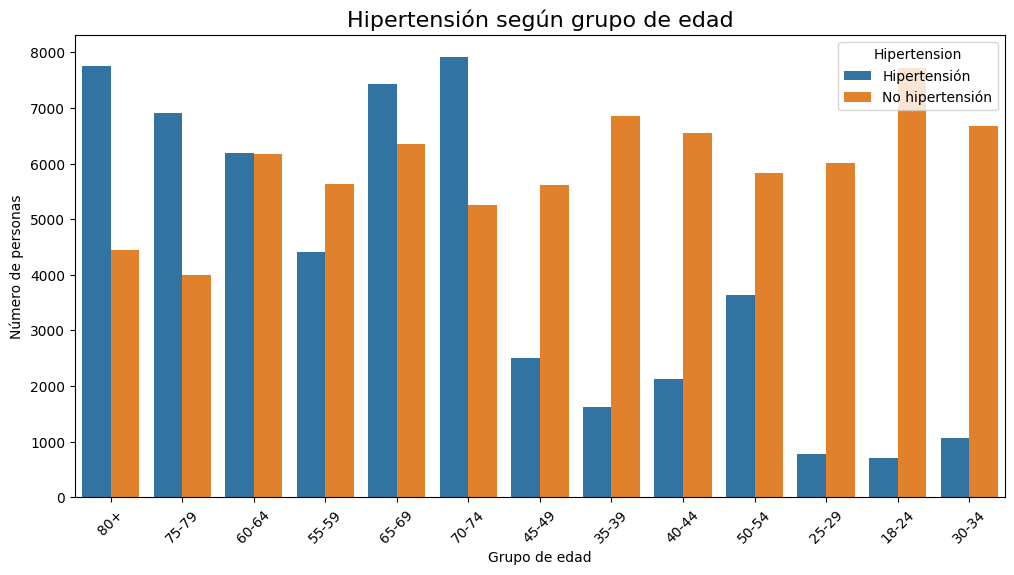

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


df_filtrado = df[
    (df['_RFHYPE6'].isin([1,2])) &
    (df['_AGEG5YR'].between(1,13))
]

edades = {
    1:'18-24',
    2:'25-29',
    3:'30-34',
    4:'35-39',
    5:'40-44',
    6:'45-49',
    7:'50-54',
    8:'55-59',
    9:'60-64',
    10:'65-69',
    11:'70-74',
    12:'75-79',
    13:'80+'
}

df_filtrado['Grupo_Edad'] = df_filtrado['_AGEG5YR'].map(edades)

df_filtrado['Hipertension'] = df_filtrado['_RFHYPE6'].map({
    1:'No hipertensión',
    2:'Hipertensión'
})


plt.figure(figsize=(12,6))

sns.countplot(
    data=df_filtrado,
    x='Grupo_Edad',
    hue='Hipertension'
)

plt.title('Hipertensión según grupo de edad', fontsize=16)
plt.xlabel('Grupo de edad')
plt.ylabel('Número de personas')

plt.xticks(rotation=45)

plt.show()

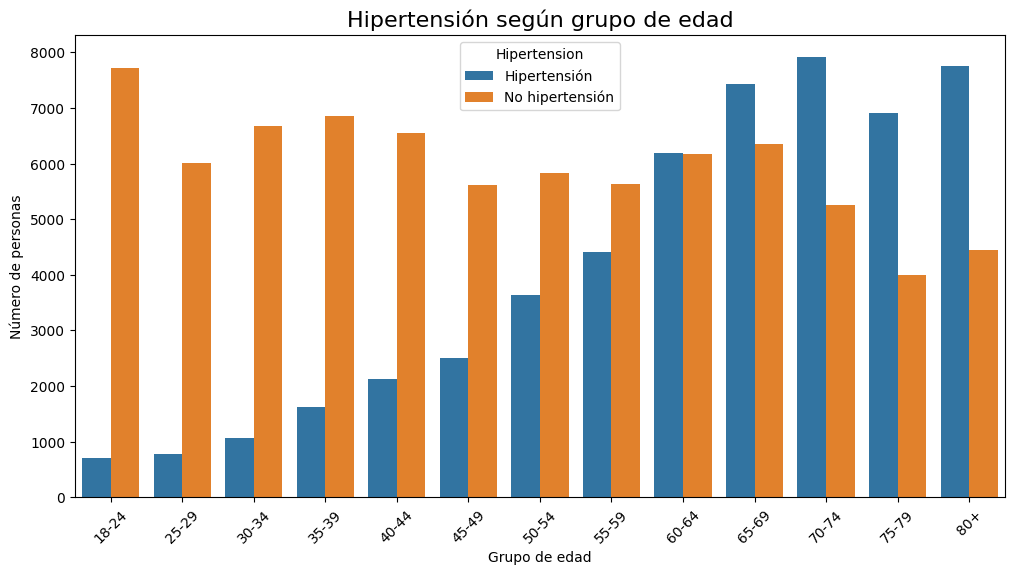

In [ ]:
plt.figure(figsize=(12,6))

orden_edades = [
    '18-24',
    '25-29',
    '30-34',
    '35-39',
    '40-44',
    '45-49',
    '50-54',
    '55-59',
    '60-64',
    '65-69',
    '70-74',
    '75-79',
    '80+'
]

sns.countplot(
    data=df_filtrado,
    x='Grupo_Edad',
    hue='Hipertension',
    order=orden_edades
)

plt.title('Hipertensión según grupo de edad', fontsize=16)
plt.xlabel('Grupo de edad')
plt.ylabel('Número de personas')

plt.xticks(rotation=45)

plt.show()

In [ ]:
# Contar hombres y mujeres

conteo_sexo = df['_SEX'].value_counts()

print(conteo_sexo)

_SEX
2.0    70293
1.0    62739
Name: count, dtype: int64


/tmp/ipykernel_4903/1996894185.py:22: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_sex['Sexo'] = df_sex['_SEX'].map(sexo_map)
/tmp/ipykernel_4903/1996894185.py:28: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_sex['Hipertension'] = df_sex['_RFHYPE6'].map({


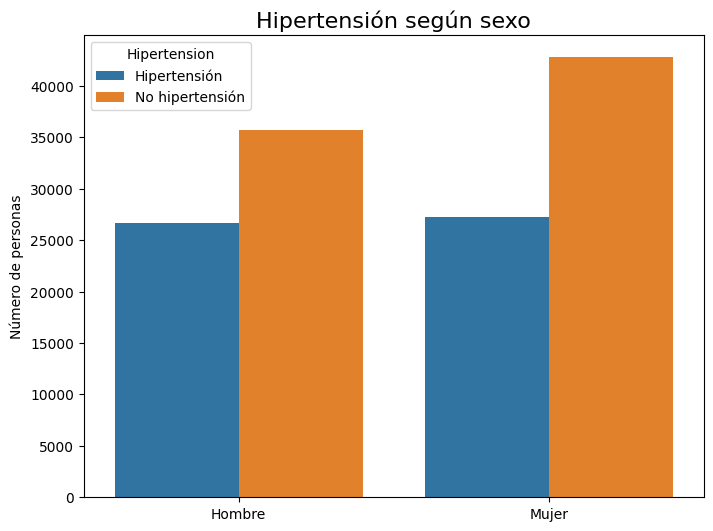

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns


df_sex = df[
    (df['_RFHYPE6'].isin([1,2])) &
    (df['_SEX'].isin([1,2]))
]

sexo_map = {
    1: 'Hombre',
    2: 'Mujer'
}

df_sex['Sexo'] = df_sex['_SEX'].map(sexo_map)

df_sex['Hipertension'] = df_sex['_RFHYPE6'].map({
    1: 'No hipertensión',
    2: 'Hipertensión'
})

plt.figure(figsize=(8,6))

sns.countplot(
    data=df_sex,
    x='Sexo',
    hue='Hipertension',
    order=['Hombre', 'Mujer']
)

plt.title('Hipertensión según sexo', fontsize=16)
plt.xlabel('')
plt.ylabel('Número de personas')

plt.show()

In [ ]:
# TABLA DE PORCENTAJES

tabla_inversa = pd.crosstab(
    df_sex['Hipertension'],
    df_sex['Sexo'],
    normalize='index'
) * 100


tabla_inversa = tabla_inversa.round(2)
print(tabla_inversa)

Sexo             Hombre  Mujer
Hipertension                  
Hipertensión      49.49  50.51
No hipertensión   45.51  54.49


In [ ]:
for estado in tabla_inversa.index:

    hombres = tabla_inversa.loc[estado, 'Hombre']
    mujeres = tabla_inversa.loc[estado, 'Mujer']

    print(f'{estado}:')
    print(f'  Hombres: {hombres}%')
    print(f'  Mujeres: {mujeres}%\n')

Hipertensión:
  Hombres: 49.49%
  Mujeres: 50.51%

No hipertensión:
  Hombres: 45.51%
  Mujeres: 54.49%



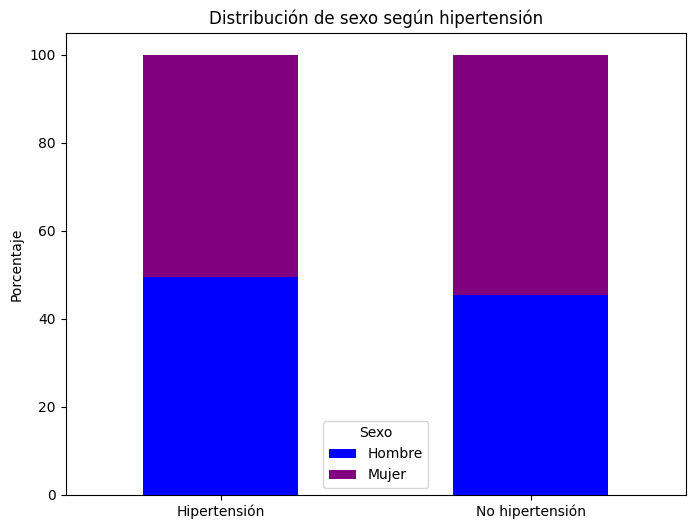

In [ ]:
tabla_inversa.plot(
    kind='bar',
    stacked=True,
    figsize=(8,6),
    color=['blue', 'purple']
)

plt.title('Distribución de sexo según hipertensión')
plt.ylabel('Porcentaje')
plt.xlabel('')

plt.xticks(rotation=0)

plt.legend(title='Sexo')

plt.show()

In [ ]:
from scipy.stats import chi2_contingency

tabla = pd.crosstab(
    df_sex['Sexo'],
    df_sex['Hipertension']
)

chi2, p, dof, expected = chi2_contingency(tabla)

print(f'Chi2 = {chi2:.4f}')
print(f'p-value = {p:.10f}')

Chi2 = 203.7238
p-value = 0.0000000000


INTENSIDAD DE ACT. FISICA


In [ ]:
# Ver cuántas personas hay en cada categoría

print(df['_PACAT3'].value_counts())

_PACAT3
1.0    48730
4.0    32893
9.0    25688
2.0    15280
3.0    10441
Name: count, dtype: int64


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df_ejercicio = df[
    (df['_RFHYPE6'].isin([1,2])) &
    (df['_PACAT3'].isin([1,2,3,4]))
]

actividad_map = {
    1: 'Muy activo',
    2: 'Activo',
    3: 'Insuf. activo',
    4: 'Inactivo'
}

df_ejercicio['Actividad'] = df_ejercicio['_PACAT3'].map(actividad_map)


df_ejercicio['Hipertension'] = df_ejercicio['_RFHYPE6'].map({
    1:'No hipertensión',
    2:'Hipertensión'
})

/tmp/ipykernel_4903/692086182.py:25: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_ejercicio['Actividad'] = df_ejercicio['_PACAT3'].map(actividad_map)
/tmp/ipykernel_4903/692086182.py:31: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_ejercicio['Hipertension'] = df_ejercicio['_RFHYPE6'].map({


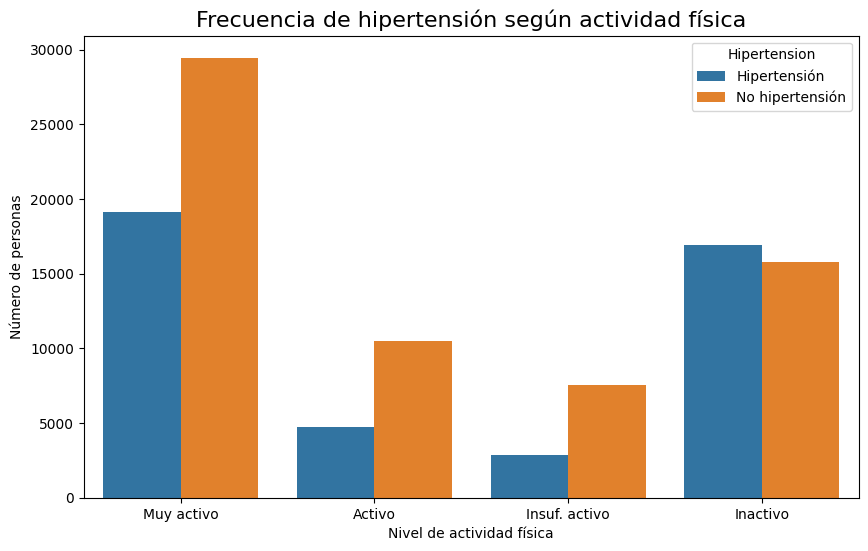

In [ ]:
plt.figure(figsize=(10,6))

orden = [
    'Muy activo',
    'Activo',
    'Insuf. activo',
    'Inactivo'
]

sns.countplot(
    data=df_ejercicio,
    x='Actividad',
    hue='Hipertension',
    order=orden
)

plt.title('Frecuencia de hipertensión según actividad física', fontsize=16)
plt.xlabel('Nivel de actividad física')
plt.ylabel('Número de personas')

plt.xticks(rotation=0)

plt.show()

FUMADORES

In [ ]:
print(df['_SMOKER3'].value_counts())

_SMOKER3
4.0    77057
3.0    34981
1.0     9642
9.0     7161
2.0     4191
Name: count, dtype: int64


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df_smoker = df[
    (df['_RFHYPE6'].isin([1,2])) &
    (df['_SMOKER3'].isin([1,2,3,4]))
]

smoker_map = {
    1:'Diario',
    2:'Ocasional',
    3:'Exfumador',
    4:'Nunca fumó'
}

df_smoker['Tabaquismo'] = df_smoker['_SMOKER3'].map(smoker_map)


df_smoker['Hipertension'] = df_smoker['_RFHYPE6'].map({
    1:'No hipertensión',
    2:'Hipertensión'
})

/tmp/ipykernel_4903/3234965833.py:25: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_smoker['Tabaquismo'] = df_smoker['_SMOKER3'].map(smoker_map)
/tmp/ipykernel_4903/3234965833.py:31: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_smoker['Hipertension'] = df_smoker['_RFHYPE6'].map({


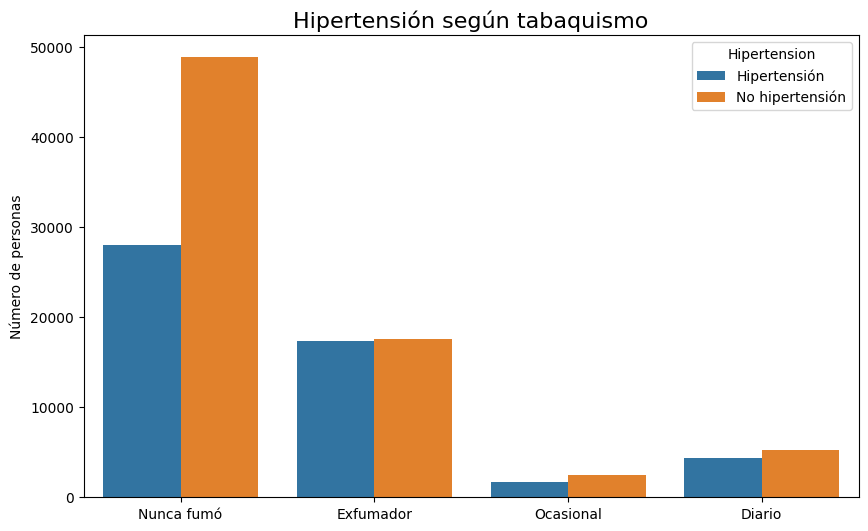

In [ ]:
orden = [
    'Nunca fumó',
    'Exfumador',
    'Ocasional',
    'Diario'
]

plt.figure(figsize=(10,6))

sns.countplot(
    data=df_smoker,
    x='Tabaquismo',
    hue='Hipertension',
    order=orden
)

plt.title('Hipertensión según tabaquismo', fontsize=16)
plt.xlabel('')
plt.ylabel('Número de personas')

plt.show()

In [ ]:
tabla_smoker = pd.crosstab(
    df_smoker['Tabaquismo'],
    df_smoker['Hipertension'],
    normalize='index'
) * 100

tabla_smoker = tabla_smoker.reindex(orden)

print(tabla_smoker.round(2))

Hipertension  Hipertensión  No hipertensión
Tabaquismo                                 
Nunca fumó           36.40            63.60
Exfumador            49.63            50.37
Ocasional            41.45            58.55
Diario               44.95            55.05


ALCOHOL

In [ ]:
print(df['DROCDY4_'].describe())

count    1.330320e+05
mean     7.920558e+01
std      2.285688e+02
min      5.397605e-79
25%      5.397605e-79
50%      3.000000e+00
75%      2.900000e+01
max      9.000000e+02
Name: DROCDY4_, dtype: float64


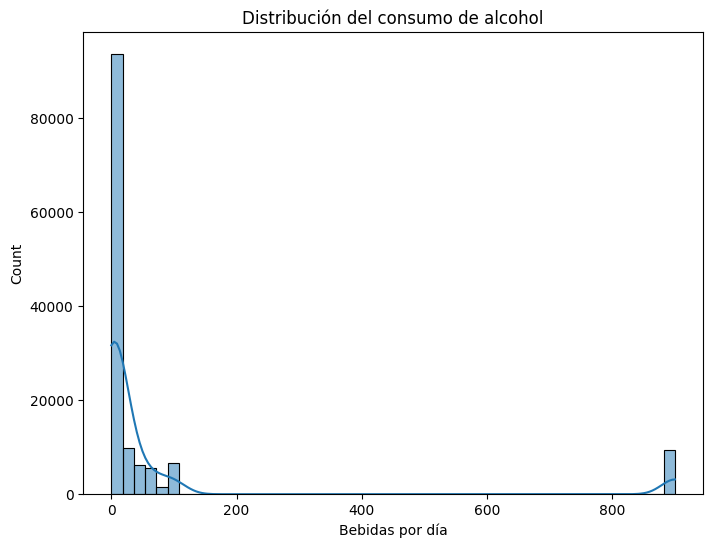

In [ ]:
plt.figure(figsize=(8,6))

sns.histplot(
    df['DROCDY4_'],
    bins=50,
    kde=True
)

plt.title('Distribución del consumo de alcohol')
plt.xlabel('Bebidas por día')

plt.show()

/tmp/ipykernel_4903/2674190682.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_alcohol['Hipertension'] = df_alcohol['_RFHYPE6'].map({


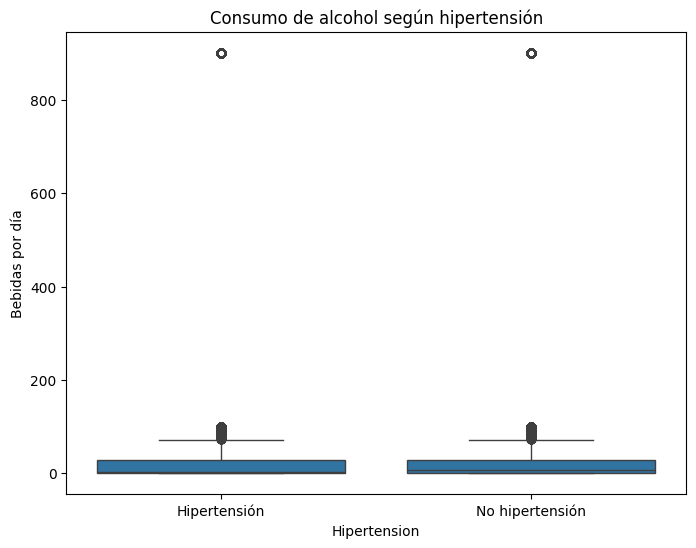

In [ ]:

df_alcohol = df[
    (df['_RFHYPE6'].isin([1,2])) &
    (df['DROCDY4_'].notna())
]

df_alcohol['Hipertension'] = df_alcohol['_RFHYPE6'].map({
    1:'No hipertensión',
    2:'Hipertensión'
})

plt.figure(figsize=(8,6))

sns.boxplot(
    data=df_alcohol,
    x='Hipertension',
    y='DROCDY4_'
)

plt.title('Consumo de alcohol según hipertensión')
plt.ylabel('Bebidas por día')

plt.show()


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df_alcohol = df[
    (df['_RFHYPE6'].isin([1,2])) &
    (df['DROCDY4_'].notna())
].copy()

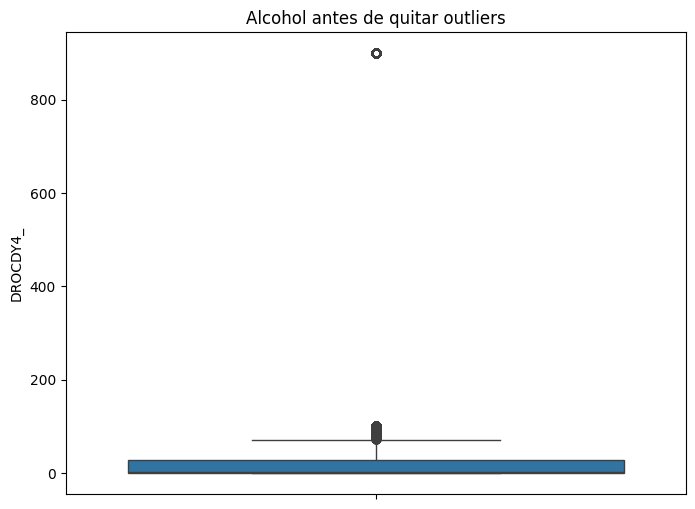

In [ ]:
plt.figure(figsize=(8,6))

sns.boxplot(
    y=df_alcohol['DROCDY4_']
)

plt.title('Alcohol antes de quitar outliers')

plt.show()

In [ ]:
Q1 = df_alcohol['DROCDY4_'].quantile(0.25)
Q3 = df_alcohol['DROCDY4_'].quantile(0.75)

IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR



df_alcohol = df_alcohol[
    (df_alcohol['DROCDY4_'] >= limite_inferior) &
    (df_alcohol['DROCDY4_'] <= limite_superior)
]

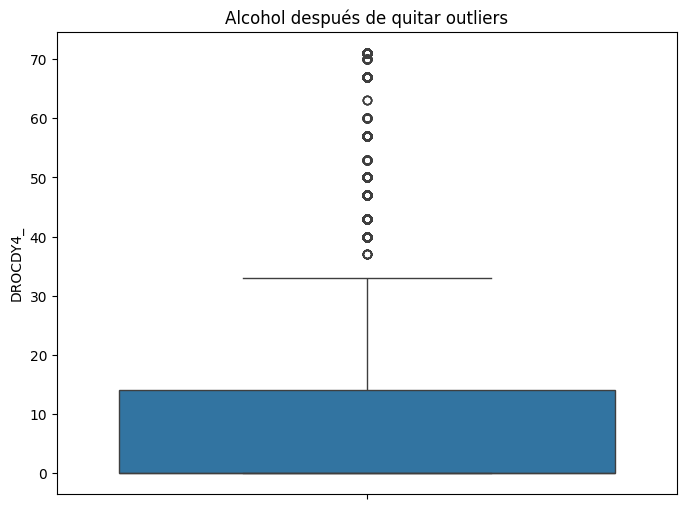

In [ ]:
plt.figure(figsize=(8,6))

sns.boxplot(
    y=df_alcohol['DROCDY4_']
)

plt.title('Alcohol después de quitar outliers')

plt.show()

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

df_alcohol['Alcohol_std'] = scaler.fit_transform(
    df_alcohol[['DROCDY4_']]
)

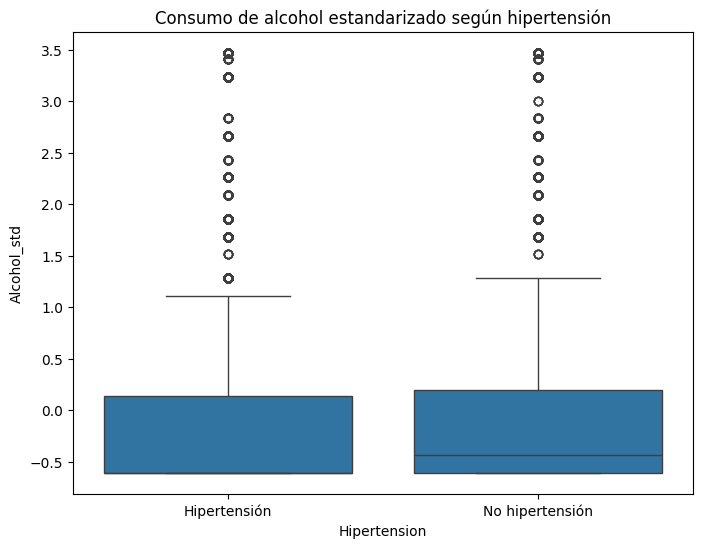

In [ ]:
df_alcohol['Hipertension'] = df_alcohol['_RFHYPE6'].map({
    1:'No hipertensión',
    2:'Hipertensión'
})

plt.figure(figsize=(8,6))

sns.boxplot(
    data=df_alcohol,
    x='Hipertension',
    y='Alcohol_std'
)

plt.title('Consumo de alcohol estandarizado según hipertensión')

plt.show()

In [ ]:
from scipy.stats import mannwhitneyu

grupo_hipertensos = df_alcohol[
    df_alcohol['_RFHYPE6'] == 2
]['Alcohol_std']

grupo_no_hipertensos = df_alcohol[
    df_alcohol['_RFHYPE6'] == 1
]['Alcohol_std']


# PRUEBA MANN-WHITNEY

stat, p = mannwhitneyu(
    grupo_hipertensos,
    grupo_no_hipertensos,
    alternative='two-sided'
)

print(f'Estadístico U: {stat:.4f}')
print(f'Valor p: {p:.10f}')

if p < 0.05:
    print('\nExiste diferencia significativa entre grupos.')
else:
    print('\nNo existe diferencia significativa entre grupos.')

Estadístico U: 1424615296.5000
Valor p: 0.0000000000

Existe diferencia significativa entre grupos.


In [ ]:
print('Hipertensos:')
print(grupo_hipertensos.median())

print('\nNo hipertensos:')
print(grupo_no_hipertensos.median())

Hipertensos:
-0.6137435281623216

No hipertensos:
-0.44144673288369674


In [ ]:
df_alcohol['Alcohol_log'] = np.log1p(
    df_alcohol['DROCDY4_']
)

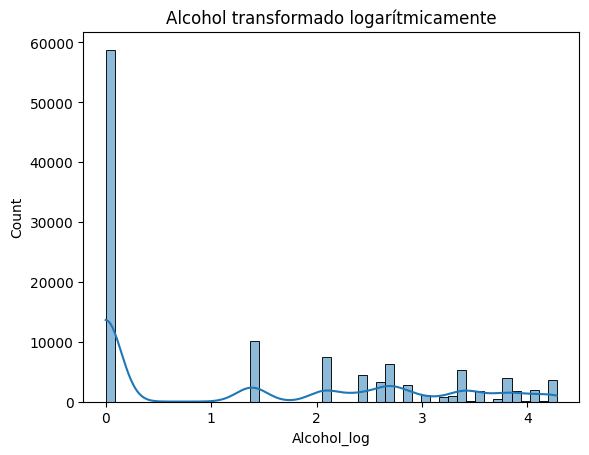

In [ ]:
sns.histplot(
    df_alcohol['Alcohol_log'],
    bins=50,
    kde=True
)

plt.title('Alcohol transformado logarítmicamente')

plt.show()

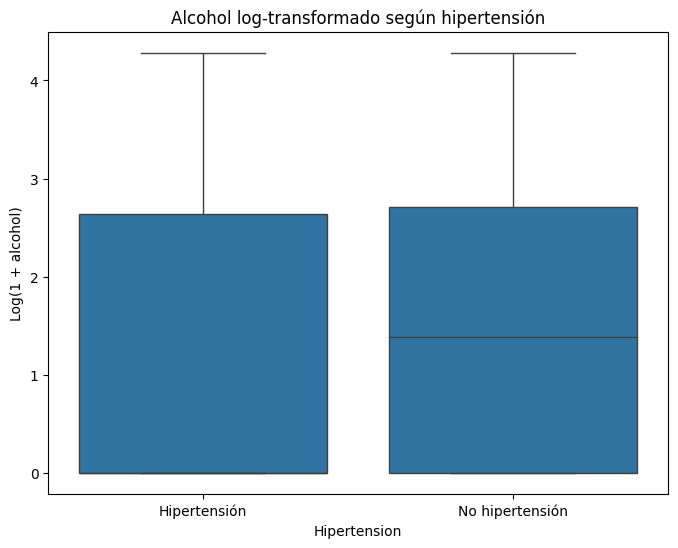

In [ ]:
plt.figure(figsize=(8,6))

sns.boxplot(
    data=df_alcohol,
    x='Hipertension',
    y='Alcohol_log'
)

plt.title('Alcohol log-transformado según hipertensión')

plt.ylabel('Log(1 + alcohol)')

plt.show()

In [ ]:
from scipy.stats import mannwhitneyu

grupo_hip = df_alcohol[
    df_alcohol['_RFHYPE6'] == 2
]['Alcohol_log']

grupo_nohip = df_alcohol[
    df_alcohol['_RFHYPE6'] == 1
]['Alcohol_log']

stat, p = mannwhitneyu(
    grupo_hip,
    grupo_nohip
)

print(f'U = {stat}')
print(f'p = {p}')

U = 1424615296.5
p = 6.158650924026685e-226


In [ ]:
print('Hipertensos:')
print(grupo_hip.median())

print('\nNo hipertensos:')
print(grupo_nohip.median())

Hipertensos:
5.397605346934028e-79

No hipertensos:
1.3862943611198906


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

df_alcohol['Alcohol_final'] = scaler.fit_transform(
    df_alcohol[['Alcohol_log']]
)

In [ ]:
df_modelo = df[
    [
        '_RFHYPE6',
        '_AGEG5YR',
        '_SEX',
        '_PACAT3',
        '_SMOKER3'
    ]
].copy()

In [ ]:
df_modelo['Alcohol'] = df_alcohol['Alcohol_log']

In [ ]:
df_modelo = df_modelo.dropna()

In [ ]:
df_modelo['Hipertension'] = df_modelo['_RFHYPE6'].map({
    1:0,
    2:1
})

In [ ]:
X = df_modelo[
    [
        '_AGEG5YR',
        '_SEX',
        '_PACAT3',
        '_SMOKER3',
        'Alcohol'
    ]
]

y = df_modelo['Hipertension']

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [ ]:
from sklearn.linear_model import LogisticRegression

modelo = LogisticRegression(max_iter=1000)

modelo.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [ ]:
y_pred = modelo.predict(X_test)

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.71      0.76      0.73     13691
           1       0.60      0.54      0.57      9285

    accuracy                           0.67     22976
   macro avg       0.66      0.65      0.65     22976
weighted avg       0.67      0.67      0.67     22976



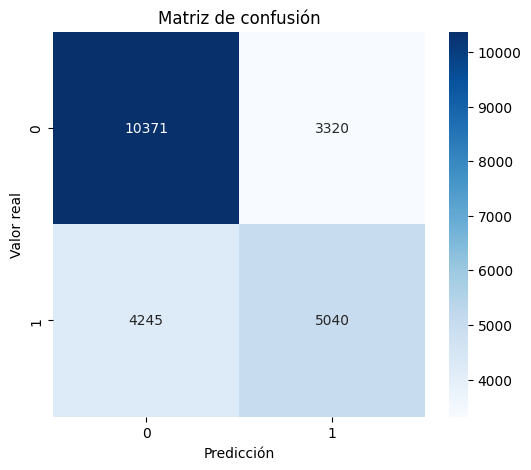

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel('Predicción')
plt.ylabel('Valor real')

plt.title('Matriz de confusión')

plt.show()

In [ ]:
coeficientes = pd.DataFrame({
    'Variable': X.columns,
    'Coeficiente': modelo.coef_[0]
})

print(coeficientes)

   Variable  Coeficiente
0  _AGEG5YR     0.238604
1      _SEX    -0.331740
2   _PACAT3     0.020909
3  _SMOKER3    -0.118994
4   Alcohol    -0.070010


In [ ]:
print(df['_BMI5'].describe())

count    120661.000000
mean       2831.180299
std         650.724581
min        1202.000000
25%        2391.000000
50%        2727.000000
75%        3138.000000
max        9984.000000
Name: _BMI5, dtype: float64


In [ ]:
df_modelo['BMI'] = df['_BMI5'] / 100

In [ ]:
print(df_modelo['BMI'].describe())

count    107530.000000
mean         28.437109
std           6.568513
min          12.020000
25%          24.030000
50%          27.370000
75%          31.580000
max          99.840000
Name: BMI, dtype: float64


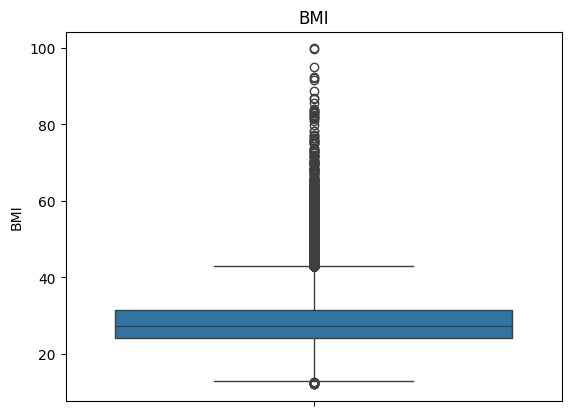

In [ ]:
sns.boxplot(y=df_modelo['BMI'])

plt.title('BMI')
plt.show()


In [ ]:
df_modelo = df_modelo[
    (df_modelo['BMI'] > 10) &
    (df_modelo['BMI'] < 60)
]

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

df_modelo['BMI_std'] = scaler.fit_transform(
    df_modelo[['BMI']]
)

In [ ]:
X = df_modelo[
    [
        '_AGEG5YR',
        '_SEX',
        '_PACAT3',
        '_SMOKER3',
        'Alcohol',
        'BMI_std'
    ]
]

In [ ]:

y = df_modelo['Hipertension']

X = df_modelo[
    [
        '_AGEG5YR',
        '_SEX',
        '_PACAT3',
        '_SMOKER3',
        'Alcohol',
        'BMI_std'
    ]
]

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

modelo = LogisticRegression(max_iter=1000)

modelo.fit(X_train, y_train)

y_pred = modelo.predict(X_test)


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.74      0.77      0.75     12794
           1       0.64      0.60      0.62      8669

    accuracy                           0.70     21463
   macro avg       0.69      0.68      0.69     21463
weighted avg       0.70      0.70      0.70     21463



In [ ]:
coeficientes = pd.DataFrame({
    'Variable': X.columns,
    'Coeficiente': modelo.coef_[0]
})

print(coeficientes.sort_values(
    by='Coeficiente',
    ascending=False
))

   Variable  Coeficiente
5   BMI_std     0.548869
0  _AGEG5YR     0.264653
2   _PACAT3     0.012631
4   Alcohol    -0.049005
3  _SMOKER3    -0.127012
1      _SEX    -0.313064


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.74      0.77      0.75     12794
           1       0.64      0.60      0.62      8669

    accuracy                           0.70     21463
   macro avg       0.69      0.68      0.69     21463
weighted avg       0.70      0.70      0.70     21463



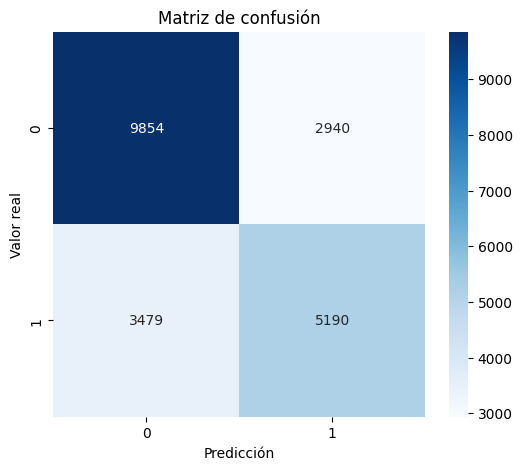

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel('Predicción')
plt.ylabel('Valor real')

plt.title('Matriz de confusión')

plt.show()

In [ ]:
coeficientes = pd.DataFrame({
    'Variable': X.columns,
    'Coeficiente': modelo.coef_[0]
})

coeficientes = coeficientes.sort_values(
    by='Coeficiente',
    ascending=False
)

print(coeficientes)

   Variable  Coeficiente
5   BMI_std     0.548869
0  _AGEG5YR     0.264653
2   _PACAT3     0.012631
4   Alcohol    -0.049005
3  _SMOKER3    -0.127012
1      _SEX    -0.313064


In [ ]:
import numpy as np

coeficientes['Odds_Ratio'] = np.exp(
    coeficientes['Coeficiente']
)

print(coeficientes)

   Variable  Coeficiente  Odds_Ratio
5   BMI_std     0.548869    1.731294
0  _AGEG5YR     0.264653    1.302979
2   _PACAT3     0.012631    1.012711
4   Alcohol    -0.049005    0.952177
3  _SMOKER3    -0.127012    0.880723
1      _SEX    -0.313064    0.731203


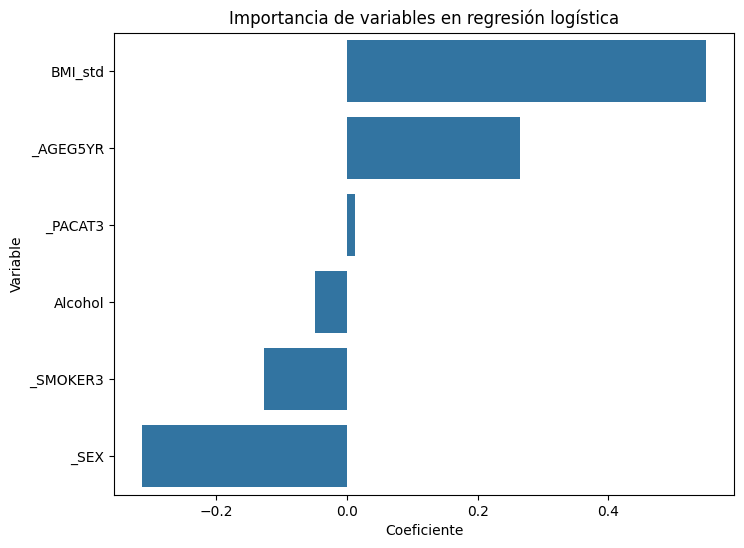

In [ ]:
plt.figure(figsize=(8,6))

sns.barplot(
    data=coeficientes,
    x='Coeficiente',
    y='Variable'
)

plt.title('Importancia de variables en regresión logística')

plt.show()

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

# modelo
modelo_rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight='balanced'
)

# entrenamiento
modelo_rf.fit(X_train, y_train)

# predicciones
y_pred_rf = modelo_rf.predict(X_test)

# métricas
print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       0.71      0.73      0.72     12794
           1       0.59      0.57      0.58      8669

    accuracy                           0.66     21463
   macro avg       0.65      0.65      0.65     21463
weighted avg       0.66      0.66      0.66     21463



   Variable  Importancia
5   BMI_std     0.567628
0  _AGEG5YR     0.218933
4   Alcohol     0.116621
2   _PACAT3     0.046317
3  _SMOKER3     0.035798
1      _SEX     0.014703


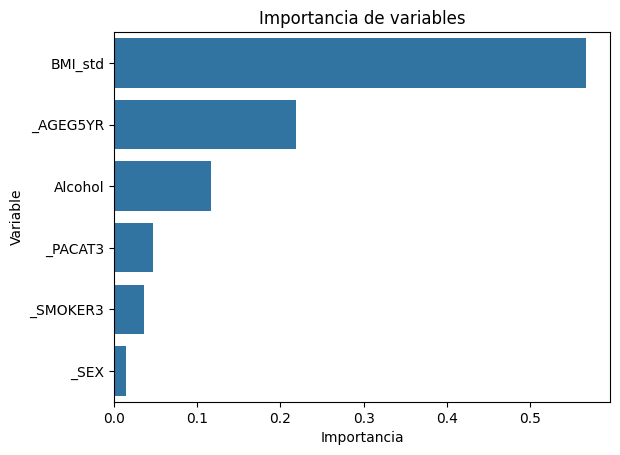

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

importancias = pd.DataFrame({
    'Variable': X.columns,
    'Importancia': modelo_rf.feature_importances_
})

importancias = importancias.sort_values(
    by='Importancia',
    ascending=False
)

print(importancias)

sns.barplot(
    data=importancias,
    x='Importancia',
    y='Variable'
)

plt.title('Importancia de variables')
plt.show()

<Axes: >

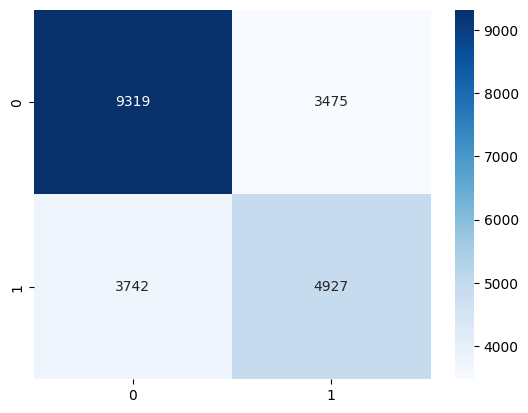

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_test, y_pred_rf)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')


In [ ]:
modelo_rf = RandomForestClassifier(
    n_estimators=500,
    max_depth=10,
    min_samples_split=10,
    class_weight='balanced',
    random_state=42
)

In [ ]:
from sklearn.metrics import accuracy_score, recall_score, f1_score
import pandas as pd


# REGRESIÓN LOGÍSTICA


acc_log = accuracy_score(y_test, y_pred)

recall_log = recall_score(y_test, y_pred)

f1_log = f1_score(y_test, y_pred)


# RANDOM FOREST


acc_rf = accuracy_score(y_test, y_pred_rf)

recall_rf = recall_score(y_test, y_pred_rf)

f1_rf = f1_score(y_test, y_pred_rf)


# TABLA

comparacion = pd.DataFrame({
    'Modelo':['Regresión Logística', 'Random Forest'],
    'Accuracy':[acc_log, acc_rf],
    'Recall HTA':[recall_log, recall_rf],
    'F1-score':[f1_log, f1_rf]
})

print(comparacion.round(3))

                Modelo  Accuracy  Recall HTA  F1-score
0  Regresión Logística     0.701       0.599     0.618
1        Random Forest     0.664       0.568     0.577


In [ ]:
import numpy as np
import pandas as pd

odds_ratios = pd.DataFrame({
    'Variable': X.columns,
    'Coeficiente': modelo.coef_[0],
})

odds_ratios['OR'] = np.exp(
    odds_ratios['Coeficiente']
)

print(odds_ratios)

   Variable  Coeficiente        OR
0  _AGEG5YR     0.264653  1.302979
1      _SEX    -0.313064  0.731203
2   _PACAT3     0.012631  1.012711
3  _SMOKER3    -0.127012  0.880723
4   Alcohol    -0.049005  0.952177
5   BMI_std     0.548869  1.731294


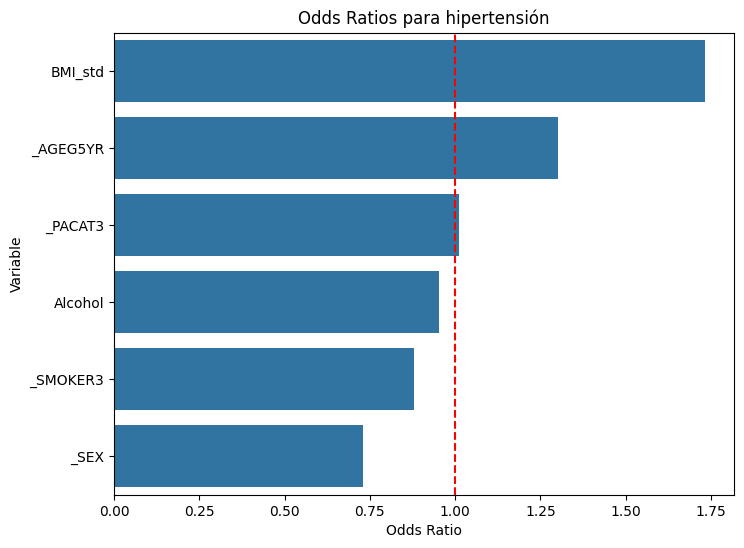

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# ordenar
odds_ratios = odds_ratios.sort_values(
    by='OR',
    ascending=False
)

# gráfica
plt.figure(figsize=(8,6))

sns.barplot(
    data=odds_ratios,
    x='OR',
    y='Variable'
)

plt.axvline(1, color='red', linestyle='--')

plt.title('Odds Ratios para hipertensión')

plt.xlabel('Odds Ratio')

plt.show()

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report

# modelo
modelo_knn = KNeighborsClassifier(
    n_neighbors=5
)

# entrenamiento
modelo_knn.fit(X_train, y_train)

# predicción
y_pred_knn = modelo_knn.predict(X_test)

# métricas
print(classification_report(
    y_test,
    y_pred_knn
))

              precision    recall  f1-score   support

           0       0.72      0.74      0.73     12794
           1       0.60      0.57      0.58      8669

    accuracy                           0.67     21463
   macro avg       0.66      0.66      0.66     21463
weighted avg       0.67      0.67      0.67     21463



In [ ]:
for k in [3,5,7,9,11]:

    modelo_knn = KNeighborsClassifier(
        n_neighbors=k
    )

    modelo_knn.fit(X_train, y_train)

    y_pred_knn = modelo_knn.predict(X_test)

    print(f'\nK = {k}')

    print(classification_report(
        y_test,
        y_pred_knn
    ))


K = 3
              precision    recall  f1-score   support

           0       0.71      0.73      0.72     12794
           1       0.58      0.56      0.57      8669

    accuracy                           0.66     21463
   macro avg       0.65      0.65      0.65     21463
weighted avg       0.66      0.66      0.66     21463


K = 5
              precision    recall  f1-score   support

           0       0.72      0.74      0.73     12794
           1       0.60      0.57      0.58      8669

    accuracy                           0.67     21463
   macro avg       0.66      0.66      0.66     21463
weighted avg       0.67      0.67      0.67     21463


K = 7
              precision    recall  f1-score   support

           0       0.73      0.75      0.74     12794
           1       0.61      0.59      0.60      8669

    accuracy                           0.68     21463
   macro avg       0.67      0.67      0.67     21463
weighted avg       0.68      0.68      0.68     21463

In [ ]:
from sklearn.metrics import accuracy_score, recall_score, f1_score
import pandas as pd

# =========================
# KNN
# =========================

acc_knn = accuracy_score(y_test, y_pred_knn)

recall_knn = recall_score(y_test, y_pred_knn)

f1_knn = f1_score(y_test, y_pred_knn)

# =========================
# TABLA COMPARATIVA
# =========================

comparacion = pd.DataFrame({
    'Modelo':[
        'Regresión Logística',
        'KNN'
    ],

    'Accuracy':[
        acc_log,
        acc_knn
    ],

    'Recall HTA':[
        recall_log,
        recall_knn
    ],

    'F1-score':[
        f1_log,
        f1_knn
    ]
})

print(comparacion.round(3))

                Modelo  Accuracy  Recall HTA  F1-score
0  Regresión Logística     0.701       0.599     0.618
1                  KNN     0.691       0.594     0.608


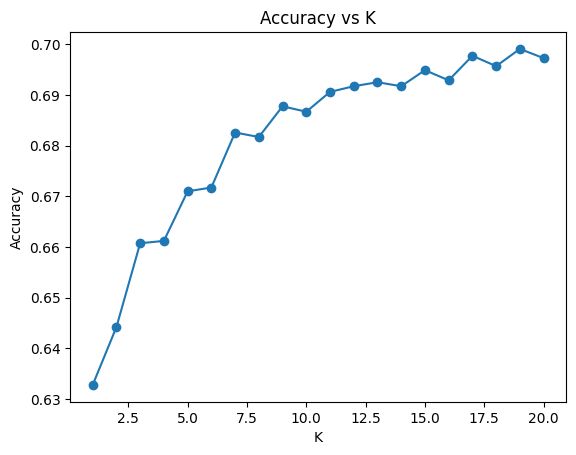

In [ ]:
ks = []
accs = []

for k in range(1,21):

    modelo_knn = KNeighborsClassifier(
        n_neighbors=k
    )

    modelo_knn.fit(X_train, y_train)

    y_pred = modelo_knn.predict(X_test)

    acc = accuracy_score(y_test, y_pred)

    ks.append(k)
    accs.append(acc)

plt.plot(ks, accs, marker='o')

plt.xlabel('K')
plt.ylabel('Accuracy')
plt.title('Accuracy vs K')

plt.show()

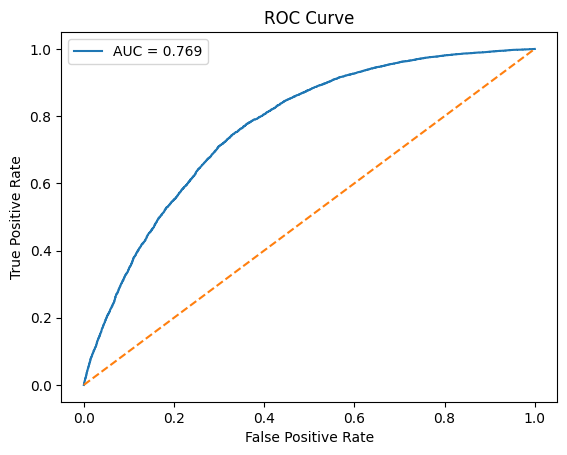

In [ ]:
from sklearn.metrics import roc_curve, auc

y_prob = modelo.predict_proba(X_test)[:,1]

fpr, tpr, _ = roc_curve(y_test, y_prob)

roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, label=f'AUC = {roc_auc:.3f}')
plt.plot([0,1],[0,1],'--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.title('ROC Curve')

plt.legend()

plt.show()

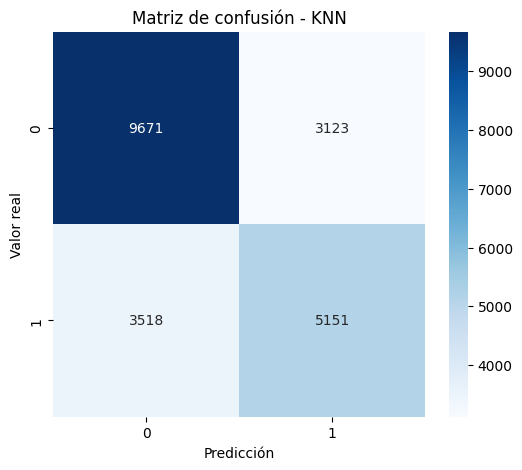

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# matriz de confusión
cm_knn = confusion_matrix(
    y_test,
    y_pred_knn
)

# gráfica
plt.figure(figsize=(6,5))

sns.heatmap(
    cm_knn,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel('Predicción')
plt.ylabel('Valor real')

plt.title('Matriz de confusión - KNN')

plt.show()